# Revision 2026-10-02 — Check I: shuffled-label control for $\lambda_1/\sum_j\lambda_j$

**Question.** The write-up reads $\lambda_1/\sum_j\lambda_j \approx 1$ (top-eigenvalue share of the final AGOP $M_T$) as evidence that a *concept* is a single direction. Is that statistic driven by the labels, or does RFM produce the same concentration on labels that carry no concept?

**Model / data.** GuppyLM (8.73M), cached last-token residual activations $a_\ell\in\mathbb{R}^{384}$, blocks $\ell=0..5$, concepts `food`, `valence`, `env_social`, train/val splits as in `rfm_guppy/cache/`. No new inference.

**Control.** Replace $y_{\text{train}}$ with a uniform random permutation $\pi(y_{\text{train}})$ (class counts preserved, label–activation association destroyed). Run the *identical* RFM code (`rfm_guppy.rfm._agop_step`, `extract_concept_vector`).

**Falsification criterion (fixed before running).** Let $s_{\text{real}}$ be the stored share for a (concept, block) and $s^{(b)}_{\text{shuf}}$, $b=1..B$, the shares under permuted labels.
- *H (statistic is concept-informative at that cell):* refuted if the permutation $p$-value $p=\frac{1+\#\{b: s^{(b)}_{\text{shuf}}\ge s_{\text{real}}\}}{1+B}$ is $\ge 0.05$, **or** if $\ge 5\%$ of shuffled runs reach $s\ge 0.95$ (the threshold under which the write-up calls a concept "rank-1").
- Tested in two regimes: **(A)** hyperparameters frozen at the values the real-label sweep selected; **(B)** the full selection pipeline re-run on shuffled train labels (selection by val $|\rho|$ against the real val labels), since the HP choice itself depends on the labels.

In [1]:
import sys, json, time, os
import numpy as np
ROOT = os.path.abspath('..'); sys.path.insert(0, ROOT)
from rfm_guppy.rfm import _agop_step, _preprocess, extract_concept_vector
CACHE = os.path.join(ROOT, 'rfm_guppy', 'cache')
CONCEPTS = ['food', 'valence', 'env_social']; NB = 6; LAM = 1e-3
OUT = 'I-shuffled-label-control_results.npz'
FORCE = True  # True: recompute A/B/C even if the .npz caches exist (overwrites them)

def load(c):
    ds = json.load(open(f'{CACHE}/concept_{c}.json'))
    y = {s: np.array([d['label'] for d in ds[s]], float) for s in ('train', 'val')}
    Z = {s: np.load(f'{CACHE}/{c}_{s}_activations.npy').astype(np.float64) for s in ('train', 'val')}
    V = dict(np.load(f'{CACHE}/{c}_vectors.npz'))
    return Z, y, V

DATA = {c: load(c) for c in CONCEPTS}
for c,(Z,y,V) in DATA.items():
    print(c, 'train', Z['train'].shape, 'pos', int(y['train'].sum()), '| val', Z['val'].shape)

food train (360, 6, 384) pos 180 | val (120, 6, 384)
valence train (120, 6, 384) pos 60 | val (40, 6, 384)
env_social train (360, 6, 384) pos 180 | val (120, 6, 384)


## 0. Reproduction gate
Before any control: recompute $s_{\text{real}}$ at the stored HPs and require agreement with the cached `lam1_share` to $10^{-4}$. If this fails, the control is not comparing like with like.

In [2]:
def run_fixed(Ztr, ytr, L, T, nz):
    Zc, mu = _preprocess(Ztr, True, nz); M = np.eye(Ztr.shape[1])
    for _ in range(T): M, _, _ = _agop_step(Zc, ytr, M, L, LAM)
    ev, U = np.linalg.eigh(M)
    return ev[::-1], U[:, -1], mu

REAL = {}
for c,(Z,y,V) in DATA.items():
    for b in range(NB):
        L, T, nz = float(V['hp_L'][b]), int(V['hp_T'][b]), bool(V['hp_normalize'][b])
        ev, u, _ = run_fixed(Z['train'][:, b], y['train'], L, T, nz)
        s = ev[0] / ev.sum(); REAL[(c, b)] = dict(s=s, L=L, T=T, nz=nz, u=u, rho=float(V['val_abs_rho'][b]))
        assert abs(s - V['lam1_share'][b]) < 1e-4, (c, b, s, V['lam1_share'][b])
        assert abs(abs(u @ V['v_per_block'][b]) - 1) < 1e-3
print('reproduction gate passed: all 18 shares and directions match the cache')

reproduction gate passed: all 18 shares and directions match the cache


## A. Frozen hyperparameters, $B=100$ permutations per cell
Also recorded: $|\cos(u_{\text{shuf}}, v_{\text{real}})|$ and the val $|\rho|$ of the shuffled direction (sign-free) — the latter tells us whether the shuffled top eigenvector still carries label information.

In [3]:
B = 100
def val_absrho(u, Zva, yva, mu, nz):
    Zc, _ = _preprocess(Zva, True, nz, mean_vec=mu); p = Zc @ u
    return abs(np.corrcoef(p, yva)[0, 1])

if not FORCE and os.path.exists(OUT):
    A = dict(np.load(OUT)); print('loaded cached', OUT)
else:
    A = {}; t0 = time.time()
    for c,(Z,y,V) in DATA.items():
        for b in range(NB):
            r = REAL[(c, b)]; rng = np.random.default_rng(1000 * CONCEPTS.index(c) + b)
            S, CO, RH = [], [], []
            for _ in range(B):
                ev, u, mu = run_fixed(Z['train'][:, b], rng.permutation(y['train']), r['L'], r['T'], r['nz'])
                S.append(ev[0] / ev.sum()); CO.append(abs(u @ r['u'])); RH.append(val_absrho(u, Z['val'][:, b], y['val'], mu, r['nz']))
            A[f'{c}_{b}_s'], A[f'{c}_{b}_cos'], A[f'{c}_{b}_rho'] = map(np.array, (S, CO, RH))
        print(c, f'{time.time()-t0:.0f}s')
    np.savez(OUT, **A)

food 79s


valence 129s


env_social 237s


In [4]:
rowsA = []
print(f"{'concept':11s}{'blk':>4s}{'σ':>6s}{'T':>4s}{'nrm':>5s} | {'s_real':>8s} {'s_shuf med':>10s} {'[q05,q95]':>16s} {'max':>7s} {'P(≥.95)':>8s} {'p':>7s} | {'ρ_real':>7s} {'ρ_shuf med':>10s} {'cos med':>8s}  verdict")
for c in CONCEPTS:
    for b in range(NB):
        r = REAL[(c, b)]; S = A[f'{c}_{b}_s']; RH = A[f'{c}_{b}_rho']; CO = A[f'{c}_{b}_cos']
        p = (1 + (S >= r['s']).sum()) / (1 + B); f95 = (S >= 0.95).mean()
        refuted = (p >= 0.05) or (f95 >= 0.05)
        rowsA.append(dict(c=c, b=b, L=r['L'], T=r['T'], nz=r['nz'], s=r['s'], med=np.median(S), q05=np.quantile(S, .05), q95=np.quantile(S, .95), mx=S.max(), f95=f95, p=p, rho=r['rho'], rho_sh=np.median(RH), cos=np.median(CO), refuted=refuted))
        print(f"{c:11s}{b:4d}{r['L']:6.0f}{r['T']:4d}{int(r['nz']):5d} | {r['s']:8.4f} {np.median(S):10.4f} [{np.quantile(S,.05):.3f},{np.quantile(S,.95):.3f}] {S.max():7.4f} {f95:8.2f} {p:7.3f} | {r['rho']:7.3f} {np.median(RH):10.3f} {np.median(CO):8.3f}  {'REFUTED' if refuted else 'holds'}")

concept     blk     σ   T  nrm |   s_real s_shuf med        [q05,q95]     max  P(≥.95)       p |  ρ_real ρ_shuf med  cos med  verdict
food          0    10   3    0 |   0.7614     0.4503 [0.365,0.553]  0.5882     0.00   0.010 |   0.906      0.346    0.098  holds
food          1     1   3    1 |   0.9788     0.6035 [0.458,0.719]  0.7832     0.00   0.010 |   0.973      0.863    0.259  holds
food          2     1   8    1 |   1.0000     0.5763 [0.420,0.752]  0.8265     0.00   0.010 |   0.975      0.852    0.228  holds
food          3     1   2    1 |   0.8864     0.5226 [0.377,0.637]  0.6801     0.00   0.010 |   0.978      0.879    0.274  holds
food          4     1   2    1 |   0.8838     0.5003 [0.376,0.606]  0.6862     0.00   0.010 |   0.977      0.873    0.302  holds
food          5     1   8    1 |   1.0000     0.5617 [0.389,0.719]  0.8481     0.00   0.010 |   0.977      0.856    0.230  holds
valence       0    10  10    0 |   0.7965     0.7557 [0.560,0.932]  0.9875     0.02   0.347 

## B. Full pipeline on shuffled labels (HP re-selected)
`extract_concept_vector` sweeps $\sigma\in\{1,10,100\}$, $T=1..10$, normalize$\in\{F,T\}$ and keeps the HP maximising val $|\rho|$. We feed it permuted *train* labels and the real val labels, $B_B=20$ per cell. This is the null for the number actually reported in the paper. The `all_results` grid is also kept to look at $s$ as a function of $(\sigma,T)$ irrespective of selection — done below for the real labels and one permutation.

In [5]:
BB = 20; OUTB = 'I-shuffled-label-control_resultsB.npz'
if not FORCE and os.path.exists(OUTB):
    Bres = dict(np.load(OUTB)); print('loaded cached', OUTB)
else:
    Bres = {}; t0 = time.time()
    for c,(Z,y,V) in DATA.items():
        for b in range(NB):
            rng = np.random.default_rng(50000 + 1000 * CONCEPTS.index(c) + b); S, RH, HP = [], [], []
            for _ in range(BB):
                v, info = extract_concept_vector(Z['train'][:, b], rng.permutation(y['train']), Z['val'][:, b], y['val'])
                S.append(info['lam1_share']); RH.append(info['val_abs_rho']); HP.append((info['L'], info['T'], info['normalize']))
            Bres[f'{c}_{b}_s'], Bres[f'{c}_{b}_rho'], Bres[f'{c}_{b}_hp'] = np.array(S), np.array(RH), np.array(HP, float)
        print(c, f'{time.time()-t0:.0f}s')
    np.savez(OUTB, **Bres)

rowsB = []
print(f"{'concept':11s}{'blk':>4s} | {'s_real':>8s} {'s_shuf med':>10s} {'max':>7s} {'P(≥.95)':>8s} {'p':>7s} | {'ρ_real':>7s} {'ρ_shuf med':>10s} {'ρ_shuf max':>10s}  verdict")
for c in CONCEPTS:
    for b in range(NB):
        r = REAL[(c, b)]; S = Bres[f'{c}_{b}_s']; RH = Bres[f'{c}_{b}_rho']
        p = (1 + (S >= r['s']).sum()) / (1 + BB); f95 = (S >= 0.95).mean(); refuted = (p >= 0.05) or (f95 >= 0.05)
        rowsB.append(dict(c=c, b=b, s=r['s'], med=np.median(S), mx=S.max(), f95=f95, p=p, rho=r['rho'], rho_sh=np.median(RH), rho_mx=RH.max(), refuted=refuted))
        print(f"{c:11s}{b:4d} | {r['s']:8.4f} {np.median(S):10.4f} {S.max():7.4f} {f95:8.2f} {p:7.3f} | {r['rho']:7.3f} {np.median(RH):10.3f} {RH.max():10.3f}  {'REFUTED' if refuted else 'holds'}")

food 370s


valence 508s


env_social 777s
concept     blk |   s_real s_shuf med     max  P(≥.95)       p |  ρ_real ρ_shuf med ρ_shuf max  verdict
food          0 |   0.7614     0.4646  0.7381     0.00   0.048 |   0.906      0.621      0.793  holds
food          1 |   0.9788     0.6030  0.8549     0.00   0.048 |   0.973      0.893      0.932  holds
food          2 |   1.0000     0.5426  0.8171     0.00   0.048 |   0.975      0.906      0.957  holds
food          3 |   0.8864     0.5585  0.8492     0.00   0.048 |   0.978      0.934      0.962  holds
food          4 |   0.8838     0.4972  0.7226     0.00   0.048 |   0.977      0.943      0.965  holds
food          5 |   1.0000     0.4217  0.6825     0.00   0.048 |   0.977      0.930      0.961  holds
valence       0 |   0.7965     0.6860  0.9458     0.00   0.333 |   0.507      0.162      0.411  REFUTED
valence       1 |   1.0000     0.6351  0.8752     0.00   0.048 |   0.899      0.389      0.679  holds
valence       2 |   0.1860     0.5245  0.8619     0.00   1.000

## C. Share as a function of $(\sigma, T)$: real vs shuffled
For each concept at its best block, and each $(\sigma,\text{normalize})$, trace $s(T)$ for the real labels and for 10 permutations. If the shuffled curves reach the same height as the real ones at the same $(\sigma,T)$, concentration is an iteration artifact; if they stay below, it is label-driven.

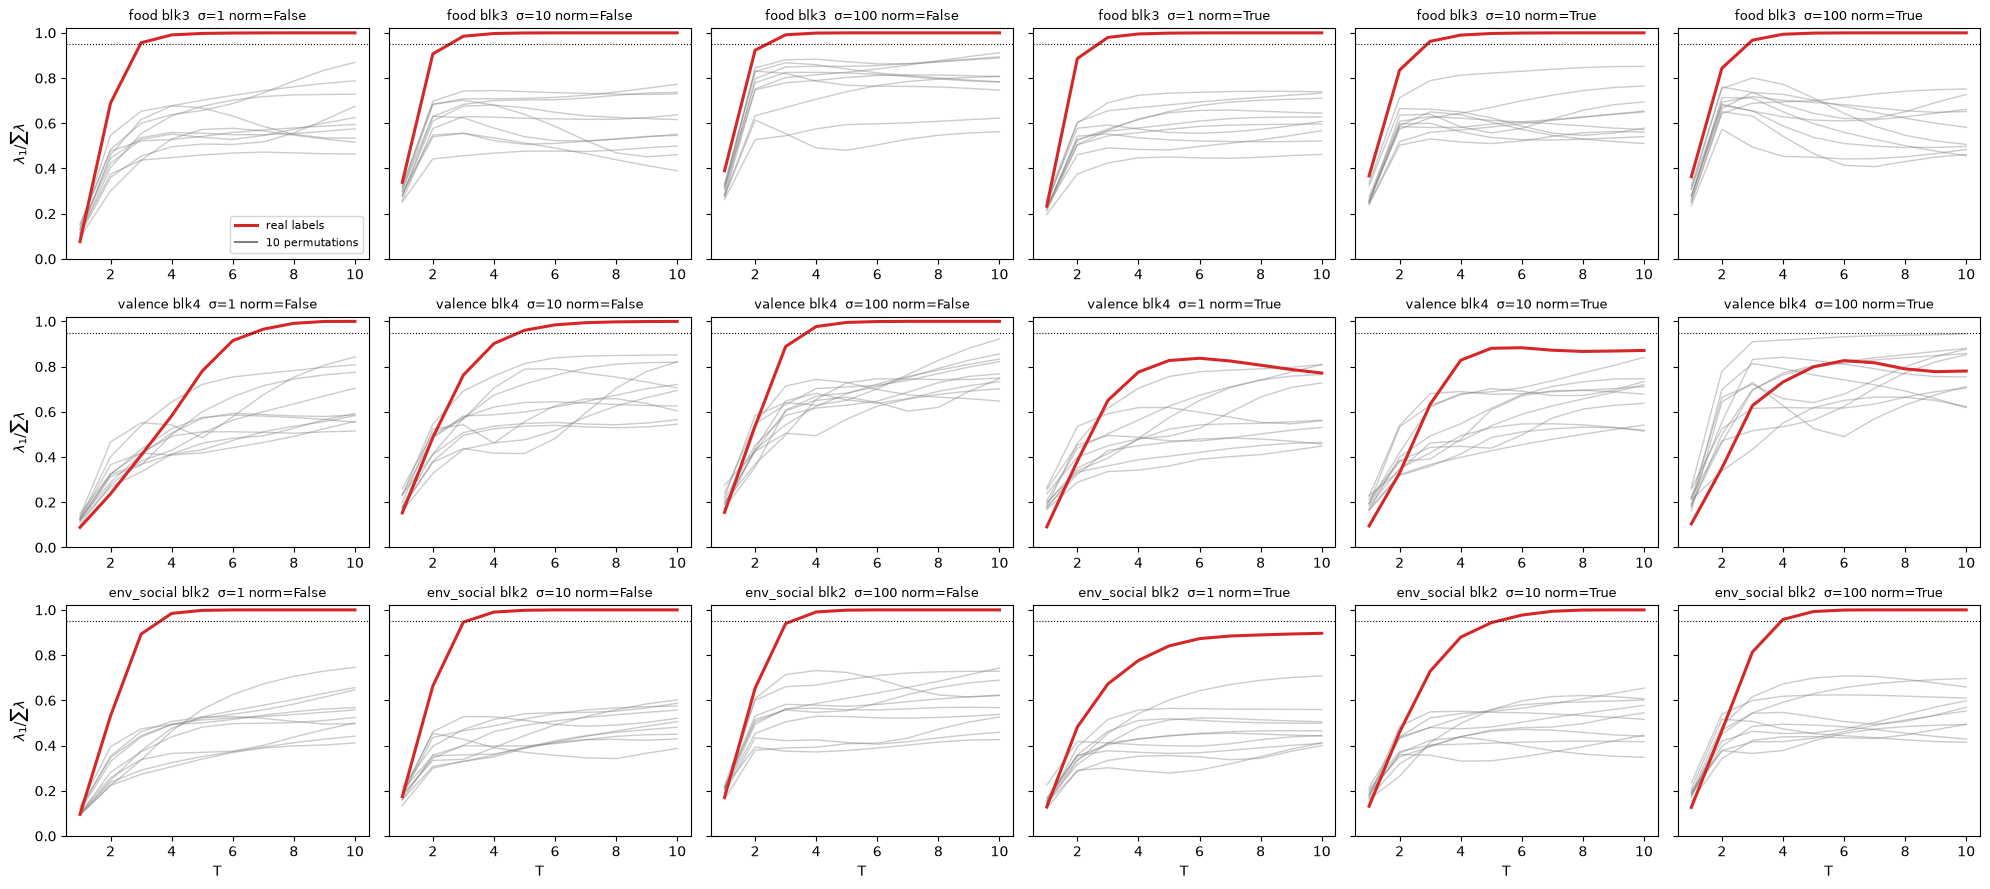

In [6]:
import matplotlib; import matplotlib.pyplot as plt
BEST = {c: int(np.argmax(DATA[c][2]['val_abs_rho'])) for c in CONCEPTS}
def trace(Ztr, ytr, L, nz, Tmax=10):
    Zc, _ = _preprocess(Ztr, True, nz); M = np.eye(Ztr.shape[1]); out = []
    for _ in range(Tmax):
        M, _, _ = _agop_step(Zc, ytr, M, L, LAM); e = np.linalg.eigvalsh(M); out.append(e[-1] / e.sum())
    return np.array(out)
OUTC = 'I-shuffled-label-control_resultsC.npz'
if not FORCE and os.path.exists(OUTC): TR = dict(np.load(OUTC))
else:
    TR = {}
    for c in CONCEPTS:
        Z, y, V = DATA[c]; b = BEST[c]; rng = np.random.default_rng(7)
        for nz in (False, True):
            for L in (1., 10., 100.):
                TR[f'{c}_{int(nz)}_{int(L)}_real'] = trace(Z['train'][:, b], y['train'], L, nz)
                TR[f'{c}_{int(nz)}_{int(L)}_shuf'] = np.stack([trace(Z['train'][:, b], rng.permutation(y['train']), L, nz) for _ in range(10)])
    np.savez(OUTC, **TR)
fig, axs = plt.subplots(3, 6, figsize=(20, 9), sharey=True); Ts = np.arange(1, 11)
for i, c in enumerate(CONCEPTS):
    for j, (nz, L) in enumerate([(n, l) for n in (0, 1) for l in (1, 10, 100)]):
        ax = axs[i, j]; sh = TR[f'{c}_{nz}_{L}_shuf']
        for row in sh: ax.plot(Ts, row, color='tab:gray', alpha=.4, lw=1)
        ax.plot(Ts, TR[f'{c}_{nz}_{L}_real'], color='tab:red', lw=2.2, label='real labels')
        ax.axhline(.95, ls=':', color='k', lw=.8)
        ax.set_title(f'{c} blk{BEST[c]}  σ={L} norm={bool(nz)}', fontsize=9); ax.set_ylim(0, 1.02)
        if i == 2: ax.set_xlabel('T')
    axs[i, 0].set_ylabel(r'$\lambda_1/\sum\lambda$')
axs[0, 0].plot([], [], color='tab:gray', label='10 permutations'); axs[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('I-shuffled-label-control_share_vs_T.png', dpi=120); plt.show()

## E. Side observation: how informative is val $|\rho|$ itself?
Regime A showed that RFM directions fit to *shuffled* labels still reach val $|\rho|\approx 0.86$ on `food`. To calibrate, compute val $|\rho|$ for (i) 2000 uniformly random unit directions $u\sim\mathrm{Unif}(S^{383})$, (ii) the top principal component of the centred train activations, (iii) the difference of class means. All use the same centring as RFM (normalize=False).

In [7]:
import pandas as pd
rngE = np.random.default_rng(123); rowsE = []
print(f"{'concept':11s}{'blk':>4s} | {'ρ_RFM':>6s} {'ρ_shufA med':>11s} | {'rand med':>8s} {'rand q95':>8s} {'rand max':>8s} | {'PC1':>6s} {'DiffM':>6s}")
for c,(Z,y,V) in DATA.items():
    for b in range(NB):
        Ztr = Z['train'][:, b]; mu = Ztr.mean(0); Zc = Ztr - mu; Zv = Z['val'][:, b] - mu
        U = rngE.standard_normal((384, 2000)); U /= np.linalg.norm(U, axis=0)
        P = Zv @ U; P = (P - P.mean(0)) / P.std(0); yv = (y['val'] - y['val'].mean()) / y['val'].std()
        R = np.abs(yv @ P) / len(yv)
        pc1 = np.linalg.svd(Zc, full_matrices=False)[2][0]
        dm = Zc[y['train'] == 1].mean(0) - Zc[y['train'] == 0].mean(0)
        r = lambda u: abs(np.corrcoef(Zv @ u, y['val'])[0, 1])
        rowsE.append(dict(c=c, b=b, rho_rfm=REAL[(c,b)]['rho'], rho_shufA=np.median(A[f'{c}_{b}_rho']), rand_med=np.median(R), rand_q95=np.quantile(R,.95), rand_max=R.max(), pc1=r(pc1), diffmeans=r(dm)))
        e = rowsE[-1]
        print(f"{c:11s}{b:4d} | {e['rho_rfm']:6.3f} {e['rho_shufA']:11.3f} | {e['rand_med']:8.3f} {e['rand_q95']:8.3f} {e['rand_max']:8.3f} | {e['pc1']:6.3f} {e['diffmeans']:6.3f}")
pd.DataFrame(rowsE).to_csv('I-shuffled-label-control_rho_baselines.csv', index=False)

concept     blk |  ρ_RFM ρ_shufA med | rand med rand q95 rand max |    PC1  DiffM
food          0 |  0.906       0.346 |    0.287    0.623    0.799 |  0.327  0.811
food          1 |  0.973       0.863 |    0.404    0.769    0.915 |  0.940  0.953
food          2 |  0.975       0.852 |    0.401    0.774    0.902 |  0.953  0.963
food          3 |  0.978       0.879 |    0.380    0.764    0.897 |  0.959  0.970
food          4 |  0.977       0.873 |    0.380    0.748    0.935 |  0.967  0.975
food          5 |  0.977       0.856 |    0.394    0.773    0.903 |  0.968  0.975
valence       0 |  0.507       0.096 |    0.117    0.326    0.507 |  0.039  0.094
valence       1 |  0.899       0.168 |    0.178    0.477    0.679 |  0.062  0.697
valence       2 |  0.908       0.158 |    0.198    0.507    0.760 |  0.252  0.746
valence       3 |  0.905       0.230 |    0.191    0.516    0.774 |  0.319  0.777


valence       4 |  0.918       0.251 |    0.183    0.487    0.703 |  0.412  0.793
valence       5 |  0.908       0.134 |    0.186    0.487    0.742 |  0.508  0.800
env_social    0 |  0.735       0.167 |    0.179    0.415    0.615 |  0.073  0.585
env_social    1 |  0.941       0.316 |    0.245    0.616    0.811 |  0.701  0.878
env_social    2 |  0.950       0.378 |    0.253    0.589    0.781 |  0.815  0.901
env_social    3 |  0.944       0.504 |    0.278    0.627    0.810 |  0.853  0.908
env_social    4 |  0.942       0.452 |    0.260    0.600    0.791 |  0.825  0.911
env_social    5 |  0.943       0.345 |    0.259    0.598    0.811 |  0.833  0.914


## D. Summary (filled in `REVIEW.md`)

In [8]:
import pandas as pd
dA = pd.DataFrame(rowsA); dB = pd.DataFrame(rowsB)
print('Regime A (frozen HP): refuted cells =', int(dA.refuted.sum()), '/ 18'); print(dA[dA.refuted][['c','b','L','T','s','med','mx','f95','p']].to_string(index=False))
print('\nRegime B (re-selected HP): refuted cells =', int(dB.refuted.sum()), '/ 18'); print(dB[dB.refuted][['c','b','s','med','mx','f95','p']].to_string(index=False))
dA.to_csv('I-shuffled-label-control_regimeA.csv', index=False); dB.to_csv('I-shuffled-label-control_regimeB.csv', index=False)

Regime A (frozen HP): refuted cells = 5 / 18
         c  b     L  T        s      med       mx  f95        p
   valence  0  10.0 10 0.796534 0.755728 0.987530 0.02 0.346535
   valence  2 100.0  1 0.185983 0.206534 0.280527 0.00 0.762376
   valence  5 100.0  1 0.147330 0.205110 0.269368 0.00 0.990099
env_social  0 100.0 10 0.813415 0.675264 0.870821 0.00 0.069307
env_social  1 100.0  1 0.221838 0.198373 0.252112 0.00 0.168317

Regime B (re-selected HP): refuted cells = 4 / 18
         c  b        s      med       mx  f95        p
   valence  0 0.796534 0.686026 0.945815  0.0 0.333333
   valence  2 0.185983 0.524500 0.861867  0.0 1.000000
   valence  5 0.147330 0.553974 0.800229  0.0 1.000000
env_social  1 0.221838 0.411707 0.674217  0.0 0.952381
